In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:

csv_path = Path("station_day.csv")
raw = pd.read_csv(csv_path, parse_dates=["Date"])

features = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene",
]

print("Размер исходной таблицы", raw.shape)
print("Доля пропусков по показателям, %")
print(raw[features + ["Xylene"]].isna().mean().mul(100).round(1))

Размер исходной таблицы (108035, 16)
Доля пропусков по показателям, %
PM2.5      20.0
PM10       39.5
NO         15.8
NO2        15.3
NOx        14.3
NH3        44.5
CO         12.0
SO2        23.3
O3         23.7
Benzene    29.1
Toluene    35.8
Xylene     78.8
dtype: float64


In [4]:
unique = raw.drop_duplicates()
clean = unique.dropna(subset=features).reset_index(drop=True)

X_raw = clean[features]
y_true = clean["AQI_Bucket"]

print("Удалено дубликатов", len(raw) - len(unique))
print("Удалено строк с пропусками в признаках", len(unique) - len(clean))
print("Осталось наблюдений и признаков", X_raw.shape)
print("Распределение категорий после очистки")
print(y_true.value_counts(dropna=False))

Удалено дубликатов 0
Удалено строк с пропусками в признаках 71471
Осталось наблюдений и признаков (36564, 11)
Распределение категорий после очистки
AQI_Bucket
Moderate        12939
Satisfactory     8396
Very Poor        4922
Poor             4893
Severe           2520
Good             2062
NaN               832
Name: count, dtype: int64


In [7]:
X_raw

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
0,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,109.26,0.17,5.92
1,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50
2,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95
3,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63
4,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02
...,...,...,...,...,...,...,...,...,...,...,...
36559,17.03,39.64,3.23,11.42,14.65,18.98,0.57,11.39,31.76,0.79,6.85
36560,9.79,19.87,23.51,16.50,40.02,25.09,0.66,10.34,30.19,0.93,6.37
36561,18.60,32.26,13.65,200.87,214.20,11.40,0.78,5.12,38.17,3.52,8.64
36562,16.07,39.30,7.56,29.13,36.69,29.26,0.69,5.88,29.64,1.86,8.40


In [6]:
y_true

0                 NaN
1            Moderate
2            Moderate
3            Moderate
4            Moderate
             ...     
36559    Satisfactory
36560            Good
36561    Satisfactory
36562    Satisfactory
36563    Satisfactory
Name: AQI_Bucket, Length: 36564, dtype: str

In [5]:
display(X_raw.corr().round(2))

means = X_raw.mean()
scales = X_raw.std(ddof=0).replace(0, 1)
X = (X_raw - means) / scales

print("Размер матрицы для кластеризации", X.shape)
print("Пропусков в матрице", X.isna().sum().sum())
display(X.head())

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
PM2.5,1.00,0.86,0.59,0.56,0.58,0.53,0.64,0.32,0.16,0.14,0.36
PM10,0.86,1.00,0.61,0.55,0.60,0.51,0.62,0.37,0.01,0.13,0.36
NO,0.59,0.61,1.00,0.65,0.87,0.42,0.65,0.29,0.04,0.19,0.35
NO2,0.56,0.55,0.65,1.00,0.76,0.40,0.56,0.37,0.26,0.12,0.28
NOx,0.58,0.60,0.87,0.76,1.00,0.44,0.62,0.33,0.13,0.18,0.29
NH3,0.53,0.51,0.42,0.40,0.44,1.00,0.44,0.26,0.13,0.05,0.22
CO,0.64,0.62,0.65,0.56,0.62,0.44,1.00,0.35,0.13,0.13,0.35
SO2,0.32,0.37,0.29,0.37,0.33,0.26,0.35,1.00,0.19,0.05,0.21
O3,0.16,0.01,0.04,0.26,0.13,0.13,0.13,0.19,1.00,-0.01,0.05
Benzene,0.14,0.13,0.19,0.12,0.18,0.05,0.13,0.05,-0.01,1.00,0.51


Размер матрицы для кластеризации (36564, 11)
Пропусков в матрице 0


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
0,-0.138418,-0.404412,-0.633033,-0.692831,-0.723052,-0.812522,-1.184415,-0.217304,1.251983,-0.306216,-0.460879
1,-0.010788,-0.337689,-0.641071,-0.697805,-0.729315,-0.882929,-1.161437,0.257432,1.593691,-0.303984,-0.442995
2,-0.049942,-0.302916,-0.645738,-0.515439,-0.675095,-0.904003,-1.138460,1.499377,1.408751,-0.302496,-0.398283
3,0.082772,-0.255181,-0.507279,-0.354625,-0.539642,-0.778037,-1.172926,2.201945,1.300853,-0.297288,-0.408150
4,-0.229690,-0.493326,-0.612030,-0.446802,-0.632815,-0.849402,-1.195904,0.655872,1.806229,-0.306216,-0.488632


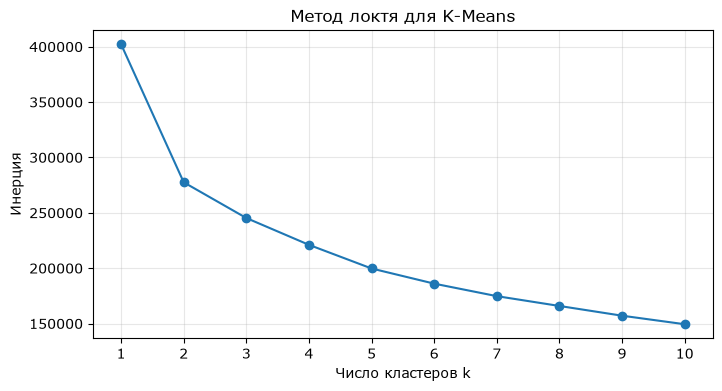

In [ ]:
from sklearn.cluster import KMeans

k_values = range(2, 11)
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42,
    )
    model.fit(X)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias, marker="o")
plt.xticks(k_values)
plt.xlabel("Число кластеров k")
plt.ylabel("Инерция")
plt.title("Метод локтя для K-Means")
plt.grid(alpha=0.3)
plt.show()

In [9]:
from sklearn.metrics import silhouette_score

scores = {}

for k in range(2, 11):
    labels = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42,
    ).fit_predict(X)

    scores[k] = silhouette_score(
        X, labels, sample_size=3000, random_state=42
    )

silhouettes = pd.Series(scores, name="Средний силуэт")
silhouettes.index.name = "k"

display(silhouettes.round(4))
print("Лучшее k по силуэту =", silhouettes.idxmax())

k
2     0.4703
3     0.3060
4     0.3066
5     0.3092
6     0.2102
7     0.2115
8     0.2247
9     0.2158
10    0.2177
Name: Средний силуэт, dtype: float64

Лучшее k по силуэту = 2


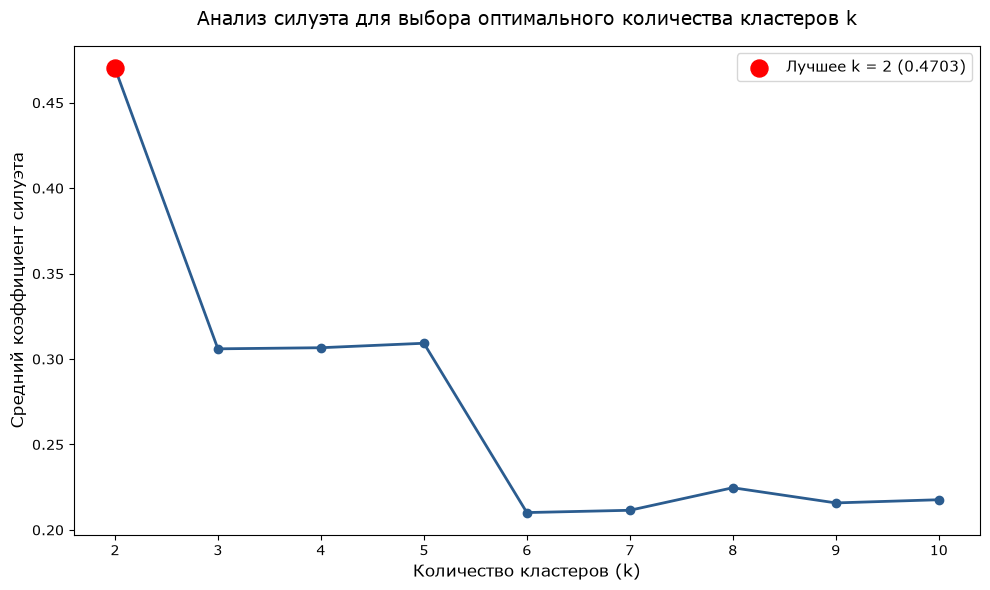

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(silhouettes.index,silhouettes.values,marker="o",linestyle="-",linewidth=2,color="#2b5c8f")


best_k = silhouettes.idxmax()
best_score = silhouettes.max()
plt.scatter(
    best_k,
    best_score,
    color="red",
    s=150,
    zorder=5,
    label=f"Лучшее k = {best_k} ({best_score:.4f})",
)
plt.title("Анализ силуэта для выбора оптимального количества кластеров k",fontsize=14,pad=15,
)
plt.xlabel("Количество кластеров (k)", fontsize=12)
plt.ylabel("Средний коэффициент силуэта", fontsize=12)
plt.xticks(silhouettes.index)  
plt.legend(fontsize=11, loc="upper right")
plt.tight_layout()
plt.show()


In [14]:
k = 2
k = best_k
initializations = ["k-means++", "random"]
seeds = range(42, 52)
runs = []
partitions = []


for init in initializations:
    for seed in seeds:
        model = KMeans(
            n_clusters=k,
            init=init,
            n_init=1,
            random_state=seed,
        ).fit(X)
        partitions.append(model.labels_.copy())

        runs.append({
            "init": init,
            "seed": seed,
            "inertia": model.inertia_,
            "iterations": model.n_iter_,
        })

results = pd.DataFrame(runs)

summary = results.groupby("init").agg(
    inertia_min=("inertia", "min"),
    inertia_mean=("inertia", "mean"),
    inertia_std=("inertia", "std"),
    iterations_mean=("iterations", "mean"),
)

display(summary.round(2))

,inertia_min,inertia_mean,inertia_std,iterations_mean
init,,,,
k-means++,277546.54,277547.01,0.33,9.7
random,277546.55,277547.09,0.27,10.7


In [15]:
results

,init,seed,inertia,iterations
0,k-means++,42,277547.319453,12
1,k-means++,43,277546.976993,12
2,k-means++,44,277547.401662,12
3,k-means++,45,277546.954431,11
4,k-means++,46,277546.769428,8
5,k-means++,47,277547.352967,6
6,k-means++,48,277546.535946,7
7,k-means++,49,277546.535946,10
8,k-means++,50,277547.319453,8
9,k-means++,51,277546.976993,11


In [22]:
from sklearn.cluster import AgglomerativeClustering

rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X), size=min(3000, len(X)), replace=False)

X_sample = X.iloc[sample_idx]

# Строка — наблюдение, столбец — запуск K-Means.
ensemble_predictions = np.column_stack([
    labels[sample_idx] for labels in partitions
])

In [23]:
n_samples = len(X_sample)
co_association = np.zeros((n_samples, n_samples), dtype=np.float32)

for labels in ensemble_predictions.T:
    same_cluster = labels[:, None] == labels[None, :]
    co_association += same_cluster

co_association /= len(partitions)
distance_matrix = 1 - co_association

In [24]:
consensus = AgglomerativeClustering(
    n_clusters=k,
    metric="precomputed",
    linkage="average",
)

ensemble_labels = consensus.fit_predict(distance_matrix)

print("Размеры кластеров", np.bincount(ensemble_labels))

Размеры кластеров [2369  631]


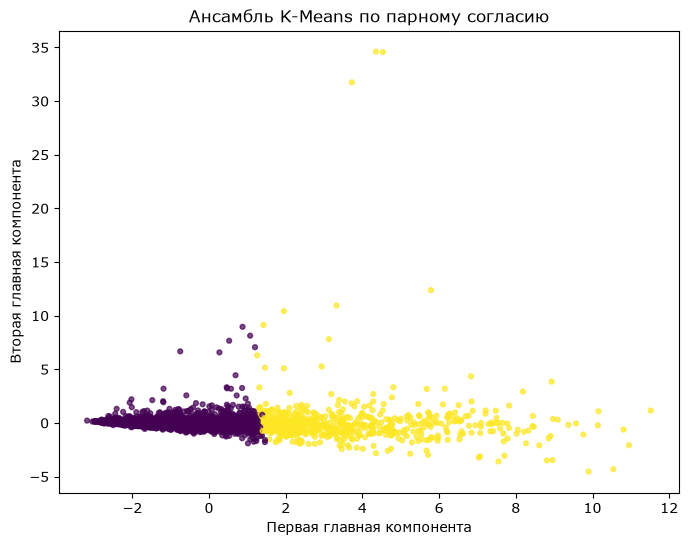

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

X_2d = PCA(n_components=2).fit_transform(X_sample)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=ensemble_labels, cmap="viridis", s=12, alpha=0.7,
)
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title("Ансамбль K-Means по парному согласию")
plt.show()

In [37]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

min_samples = 12
naive_labels = DBSCAN(eps=0.3, min_samples=5).fit_predict(X)

noise = naive_labels == -1
print("Число кластеров", np.unique(naive_labels[~noise]).size)

Число кластеров 152


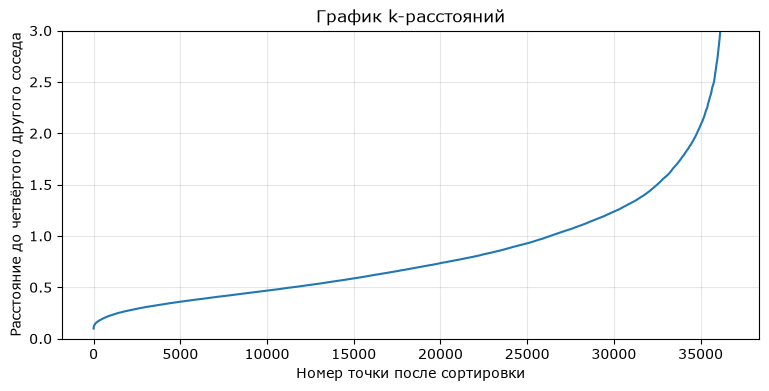

In [38]:
neighbors = NearestNeighbors(
    n_neighbors=min_samples,
    metric="euclidean",
).fit(X)

distances, _ = neighbors.kneighbors(X)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(k_distances)
plt.ylim(0, 3)
plt.xlabel("Номер точки после сортировки")
plt.ylabel("Расстояние до четвёртого другого соседа")
plt.title("График k-расстояний")
plt.grid(alpha=0.3)
plt.show()

In [39]:
rows = []
labels_by_eps = {}

for eps in [1.55, 1.6, 1.7]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    labels_by_eps[eps] = labels

    noise = labels == -1
    sizes = pd.Series(labels[~noise]).value_counts()

    rows.append({
        "eps": eps,
        "Число кластеров": len(sizes),
        "Шум, %": round(100 * noise.mean(), 2),
        "Размер крупнейшего кластера": sizes.max(),
    })

display(pd.DataFrame(rows))

,eps,Число кластеров,"Шум, %",Размер крупнейшего кластера
0,1.55,6,6.19,34155
1,1.60,6,5.54,34388
2,1.70,5,4.40,34795


# Исследование чувствительности алгоритма к шумам и выбросам

In [43]:
from sklearn.metrics import adjusted_rand_score

eps = 1.55          # Подставь выбранный радиус
min_samples = 12  # Подставь выбранное целое число

X_array = X.to_numpy()
n_original, n_features = X_array.shape
n_outliers = round(0.01 * n_original)

rng = np.random.default_rng(42)
source_rows = rng.choice(n_original, size=n_outliers, replace=False)
feature_ids = rng.integers(n_features, size=n_outliers)

outliers = X_array[source_rows].copy()
high_values = X.quantile(0.99).to_numpy()

outliers[np.arange(n_outliers), feature_ids] = (
    high_values[feature_ids] + rng.uniform(3, 6, size=n_outliers)
)

X_modified = np.vstack([X_array, outliers])

In [44]:
dbscan = DBSCAN(eps=eps, min_samples=min_samples, algorithm="brute")

baseline_labels = dbscan.fit_predict(X_array)
modified_labels = dbscan.fit_predict(X_modified)

original_after = modified_labels[:n_original]
outlier_labels = modified_labels[n_original:]

KeyboardInterrupt: 

In [ ]:
def cluster_summary(labels):
    noise = labels == -1
    _, sizes = np.unique(labels[~noise], return_counts=True)

    return {
        "Число кластеров": len(sizes),
        "Шум, %": 100 * noise.mean(),
        "Крупнейший кластер": sizes.max(initial=0),
    }


summary = pd.DataFrame(
    [cluster_summary(baseline_labels), cluster_summary(original_after)],
    index=["До добавления выбросов", "После добавления выбросов"],
)
display(summary.round(2))

noise_before = baseline_labels == -1
noise_after = original_after == -1

print("Выбросов помечено как шум", (outlier_labels == -1).sum(), "из", n_outliers)
print("Перешло из кластера в шум", (~noise_before & noise_after).sum())
print("Перешло из шума в кластер", (noise_before & ~noise_after).sum())

in_clusters_both = ~noise_before & ~noise_after
if in_clusters_both.sum() >= 2:
    ari = adjusted_rand_score(
        baseline_labels[in_clusters_both],
        original_after[in_clusters_both],
    )
    print(f"ARI для точек, оставшихся в кластерах {ari:.4f}")

,Число кластеров,"Шум, %",Крупнейший кластер
До добавления выбросов,6,6.19,34155
После добавления выбросов,6,6.18,34158


Выбросов помечено как шум 311 из 366
Перешло из кластера в шум 0
Перешло из шума в кластер 7
ARI для точек, оставшихся в кластерах 1.0000
